# SVM_Final_Model
1. Recreate the **same** 70/15/15 split used in Part 1 (same preprocessing + seed)
2. Train on the **whole** 70% training set with the tuned hyperparameters
3. Report final metrics on the 15% test set

## [1] Imports, paths and data loading

In [1]:
from pathlib import Path
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    f1_score,
)

input_file = (
    Path.home() / "Documents" / "AIE410_Project"
    / "Data_Preprocessed" / "Data_output.parquet"
)
project_dir = Path.home() / "Documents" / "AIE410_Project" / "SVM_TFIDF"
hyperparameter_dir = project_dir / "Hyperparameter_Tuning_Results"
model_results_dir = project_dir / "Model_Results"
model_results_dir.mkdir(parents=True, exist_ok=True)

hyperparams_file = hyperparameter_dir / "best_hyperparameters.json"
model_file = model_results_dir / "jasc_linear_svm_Final.joblib"
report_file = model_results_dir / "jasc_svm_classification_report_Final.csv"
predictions_file = model_results_dir / "jasc_svm_test_predictions_Final.csv"
confusion_matrix_file = model_results_dir / "jasc_svm_confusion_matrix_Final.png"
metrics_file = model_results_dir / "jasc_svm_v2_final_metrics_Final.txt"

for p in [input_file, hyperparams_file]:
    if not p.exists():
        raise FileNotFoundError(f"File not found: {p}  (run the tuning notebook first)")

df = pd.read_parquet(input_file)

required_columns = ["JASCCode", "Discrepancy"]
missing_columns = [c for c in required_columns if c not in df.columns]
if missing_columns:
    raise ValueError(f"Missing columns: {missing_columns}")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (1765824, 76)


,OperatorControlNumber,DifficultyDate,SubmissionDate,OperatorDesignator,SubmitterDesignator,SubmitterTypeCode,ReceivingRegionCode,ReceivingDistrictOffice,SDRType,JASCCode,...,ButtLineFromSide,ButtlineTo,ButtlineToSide,WaterLineFrom,WaterLineTo,CrackLength,NumberOfCracks,CorrosionLevel,StructuralOther,Discrepancy
0,95UALD10001,01/03/1995,2000-03-26T17:11:31.060-05:00,UALA,<NA>,A,WP,29,A,3397,...,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,EEL LIGHT ON RT AISLE B ZONE INOPERATIVE. REP...
1,9500042202,01/03/1995,2000-03-26T17:11:31.060-05:00,NWAA,NWAA,A,GL,01,A,2741,...,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,"DURING 5 DEGREE FLAP TAKEOFF AT 20 KNOTS, CENT..."
2,95UALD10002,01/03/1995,2000-03-26T17:11:31.060-05:00,UALA,<NA>,A,WP,29,A,3397,...,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,EEL STRIP LIGHT IN B ZONE LEFT AND RIGHT SIDE ...
3,95UAL757001,01/04/1995,2000-03-26T17:11:31.060-05:00,UALA,UALA,A,WP,29,A,2560,...,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,"DURING OVERHAUL OF THE RIGHT OFF-WING SLIDE, T..."
4,CKSA94353,01/03/1995,2000-03-26T17:11:31.060-05:00,CKSA,CKSA,A,GL,23,A,7250,...,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,"KMCI - FLT 59901 - ON CLIMB-OUT, NR 3 ENGINE H..."


## [2] NLTK / HTTPS setup

In [2]:
import os
import ssl
import certifi

os.environ["SSL_CERT_FILE"] = certifi.where()
os.environ["REQUESTS_CA_BUNDLE"] = certifi.where()
ssl._create_default_https_context = ssl.create_default_context

import re
import nltk
from functools import lru_cache
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer, PorterStemmer

for pkg in ["stopwords", "wordnet", "omw-1.4"]:
    nltk.download(pkg, quiet=True)

## [3] Text cleaning and preprocessing
**Keep this cell identical in both notebooks** so the cleaned data (and therefore the split) is identical.

In [ ]:
# Use ALL data here: the 100k / 25k sampling for tuning happens AFTER the split
SAMPLE_SIZE = None
RANDOM_STATE = 42
NORMALIZATION = "lemma"   # "lemma", "stem", or None

STOP_WORDS = set(stopwords.words("english")) - {"no", "not", "nor", "without"}

_norm = {
    "lemma": WordNetLemmatizer().lemmatize,
    "stem": PorterStemmer().stem,
}.get(NORMALIZATION, lambda t: t)
_norm = lru_cache(maxsize=None)(_norm)


def preprocess_text(text):
    tokens = re.sub(r"[\W_]+", " ", str(text).lower()).split()
    return " ".join(_norm(t) for t in tokens if t not in STOP_WORDS)


data = df[["Discrepancy", "JASCCode"]].copy()
data["Discrepancy"] = data["Discrepancy"].astype("string").str.strip()
data["JASCCode"] = pd.to_numeric(data["JASCCode"], errors="coerce")
data = data.dropna()
data = data[
    (data["Discrepancy"] != "")
    & (data["JASCCode"] >= 0)
    & (data["JASCCode"] % 1 == 0)
]

# JASC category = first two digits of the code (e.g. 3210 -> "32")
data["JASC_Category"] = data["JASCCode"].astype("int64").astype(str).str[:2]

if SAMPLE_SIZE and len(data) > SAMPLE_SIZE:
    data = data.sample(SAMPLE_SIZE, random_state=RANDOM_STATE)

data["Clean_Text"] = data["Discrepancy"].map(preprocess_text)

data = (
    data[data["Clean_Text"] != ""]
    .drop_duplicates(["Clean_Text", "JASC_Category"])
    .sample(frac=1, random_state=RANDOM_STATE)
    .reset_index(drop=True)
)

X, y = data["Clean_Text"], data["JASC_Category"]
print(f"Samples: {len(data):,} | Categories: {y.nunique():,}")
display(y.value_counts().sort_index().rename("SampleCount").to_frame())
display(data[["Discrepancy", "Clean_Text", "JASC_Category"]].head())

Samples: 99,269 | Categories: 50


,SampleCount
JASC_Category,
11,72
12,5
14,57
18,2
21,2689
22,421
23,417
24,1133
25,4367


,Discrepancy,Clean_Text,JASC_Category
0,FOS NR 2 WINDOW FELL OFF WHEN TRYING TO CLOSE....,fo nr 2 window fell trying close acft grounded...,56
1,NR 4 MAIN CARGO DOOR JAM SUPPORT FITTING P/N A...,nr 4 main cargo door jam support fitting p n a...,53
2,AFT CARGO WATER TANK SUPPORT BRACKET CRACKED S...,aft cargo water tank support bracket cracked s...,53
3,INSPECTION FOUND FUSELAGE SKIN CORRODED AT STA...,inspection found fuselage skin corroded sta 68...,53
4,CURL ASSY HAS EXCESSIVE BURN IN SOME AREAS. R...,curl assy excessive burn area replaced new uni...,72


## [4] Split: 70% train / 15% validation / 15% test
Fixed `RANDOM_STATE` + identical preprocessing => identical split in both notebooks.

In [4]:
TRAIN_FRAC, VAL_FRAC, TEST_FRAC = 0.70, 0.15, 0.15

class_counts = y.value_counts()
if len(data) < 20:
    raise ValueError("Not enough samples for a 70/15/15 split.")
if y.nunique() < 2:
    raise ValueError("At least 2 distinct JASC categories are required.")

# Stratify only if every category is large enough to appear in all three splits
can_stratify = class_counts.min() >= 5

# Step 1: 70% train vs 30% temp
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=VAL_FRAC + TEST_FRAC,
    random_state=RANDOM_STATE,
    stratify=y if can_stratify else None,
)
# Step 2: split the 30% temp half/half -> 15% validation, 15% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=TEST_FRAC / (VAL_FRAC + TEST_FRAC),
    random_state=RANDOM_STATE,
    stratify=y_temp if can_stratify else None,
)

print(f"Stratified split: {can_stratify}")
print(f"Train: {len(X_train):,} ({len(X_train)/len(data):.1%})")
print(f"Val:   {len(X_val):,} ({len(X_val)/len(data):.1%})")
print(f"Test:  {len(X_test):,} ({len(X_test)/len(data):.1%})")

Stratified split: False
Train: 69,488 (70.0%)
Val:   14,890 (15.0%)
Test:  14,891 (15.0%)


## [5] Load tuned hyperparameters

In [11]:
with open(hyperparams_file) as f:
    saved_hp = json.load(f)

best_params = saved_hp["best_params"]
if "tfidf__ngram_range" in best_params:
    best_params["tfidf__ngram_range"] = tuple(best_params["tfidf__ngram_range"])

print(f"Best CV score from tuning ({saved_hp['scoring']}): {saved_hp['best_cv_score']:.4f}")
for k, v in best_params.items():
    print(f"  {k}: {v}")

Best CV score from tuning (f1_macro): 0.6318
  classifier__C: 0.3920379472728675
  classifier__class_weight: balanced
  tfidf__min_df: 2
  tfidf__ngram_range: (1, 1)


## [6] Train on the full 70% training set

In [12]:
model = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        strip_accents="unicode",
        sublinear_tf=True,       
        min_df=2,                # default, overridden by best_params
        ngram_range=(1, 2),      # default, overridden by best_params
    )),
    ("classifier", LinearSVC(
        dual="auto",
        max_iter=5000,
        random_state=RANDOM_STATE,
        loss="squared_hinge",     # Use squared hinge loss to learn classification boundaries
        class_weight="balanced",  # Give more weight to categories with fewer samples
        tol=1e-4,                 # Set the tolerance for determining convergence
    )),
])


# Apply the best parameters found during hyperparameter tuning
model.set_params(**best_params)

print(f"Training on {len(X_train):,} samples...")

model.fit(X_train, y_train)

print("Training completed.")
print("TF-IDF features:", len(model.named_steps["tfidf"].vocabulary_))
print("Classes learned:", len(model.named_steps["classifier"].classes_))


Training on 69,488 samples...
Training completed.
TF-IDF features: 19921
Classes learned: 50


## [7] Final evaluation on the test set (15%)

In [13]:
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
macro_f1 = f1_score(y_test, y_pred, average="macro", zero_division=0)
weighted_f1 = f1_score(y_test, y_pred, average="weighted", zero_division=0)

print(f"Test samples: {len(X_test):,}")
print(f"Accuracy:    {accuracy:.4f}")
print(f"Macro F1:    {macro_f1:.4f}")
print(f"Weighted F1: {weighted_f1:.4f}")
print("\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))

Test samples: 14,891
Accuracy:    0.8948
Macro F1:    0.6690
Weighted F1: 0.8960

Classification report:
              precision    recall  f1-score   support

          11       0.82      1.00      0.90         9
          14       0.20      0.17      0.18         6
          18       0.00      0.00      0.00         1
          21       0.84      0.89      0.87       389
          22       0.64      0.70      0.67        54
          23       0.77      0.80      0.78        74
          24       0.80      0.82      0.81       161
          25       0.87      0.84      0.86       654
          26       0.83      0.91      0.87       184
          27       0.86      0.78      0.82       369
          28       0.73      0.83      0.78       132
          29       0.76      0.90      0.82       136
          30       0.74      0.77      0.76       102
          31       0.44      0.35      0.39        66
          32       0.91      0.89      0.90       548
          33       0.98      0

## [8] Save model, metrics, report, predictions and confusion matrix

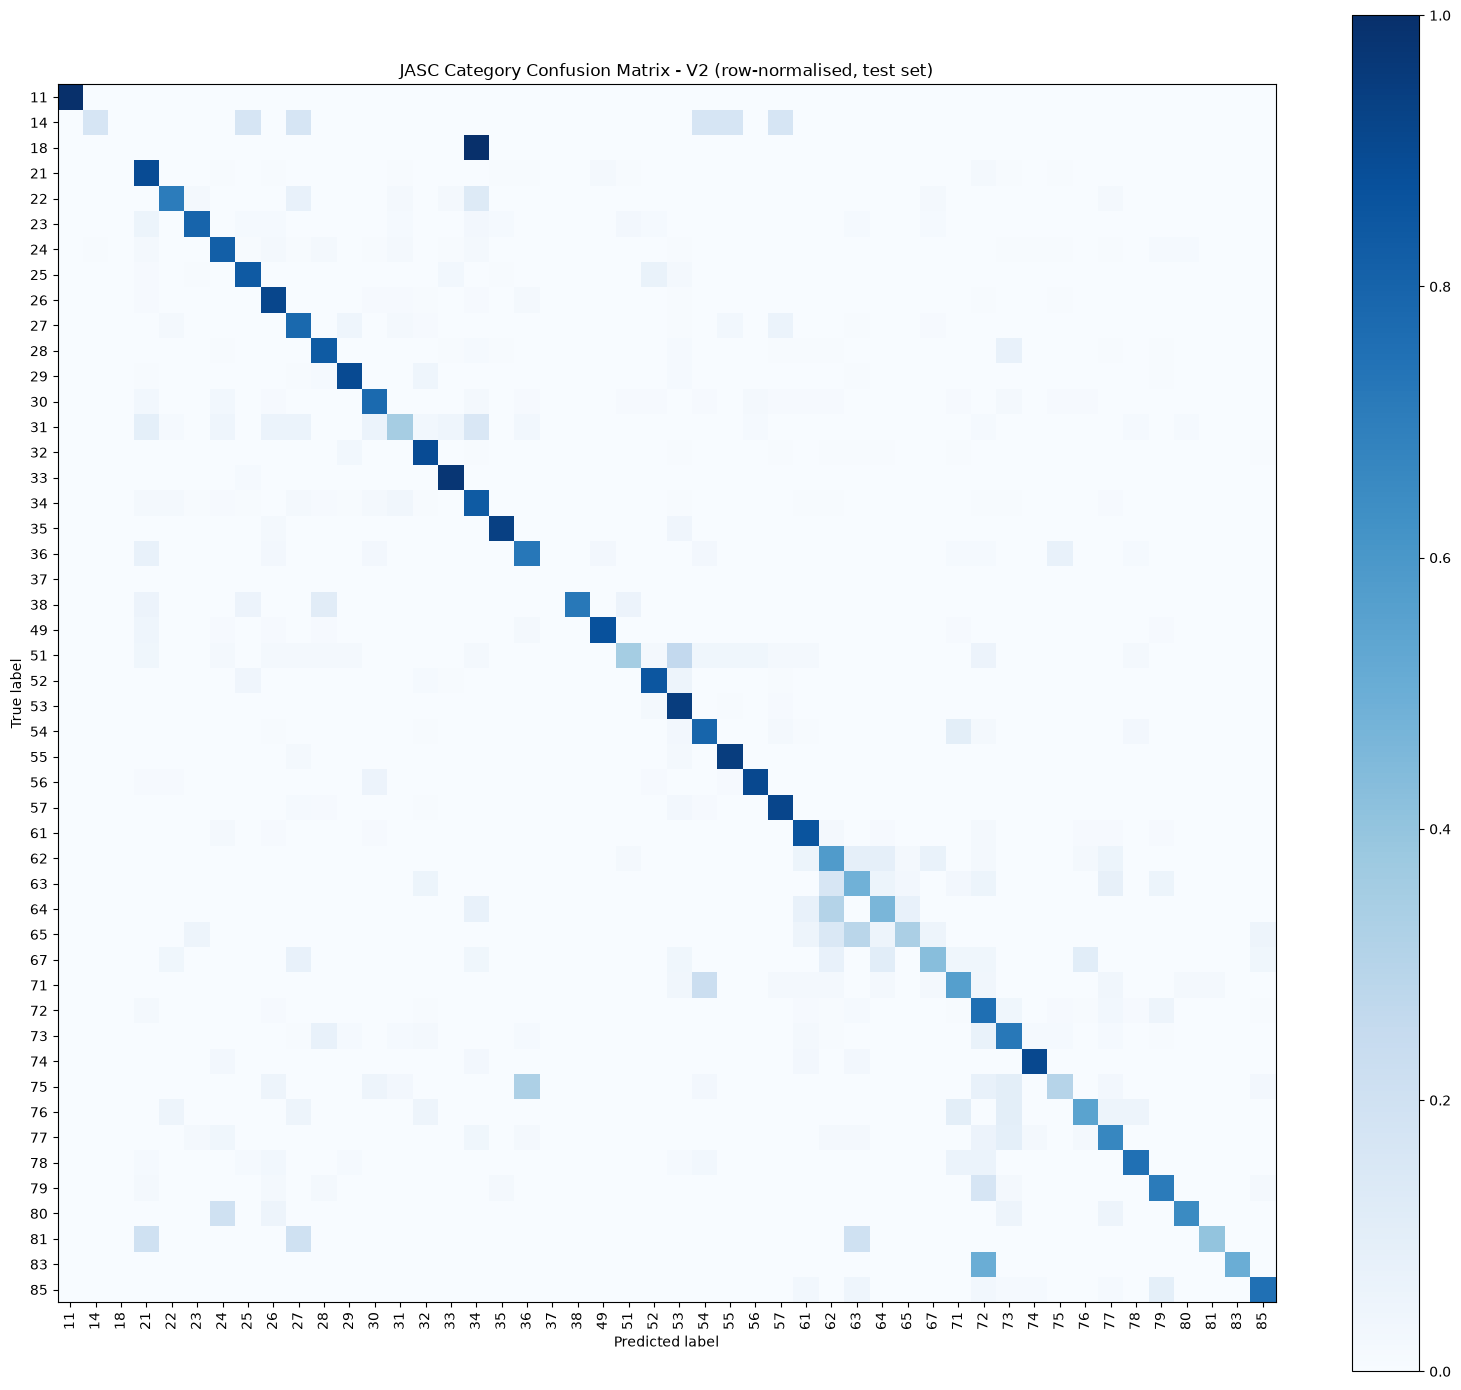

Saved:
 - /Users/nileshsaumyadasa/Documents/AIE410_Project/SVM_TFIDF/Model_Results/jasc_linear_svm_Final.joblib
 - /Users/nileshsaumyadasa/Documents/AIE410_Project/SVM_TFIDF/Model_Results/jasc_svm_classification_report_Final.csv
 - /Users/nileshsaumyadasa/Documents/AIE410_Project/SVM_TFIDF/Model_Results/jasc_svm_test_predictions_Final.csv
 - /Users/nileshsaumyadasa/Documents/AIE410_Project/SVM_TFIDF/Model_Results/jasc_svm_confusion_matrix_Final.png
 - /Users/nileshsaumyadasa/Documents/AIE410_Project/SVM_TFIDF/Model_Results/jasc_svm_v2_final_metrics_Final.txt


In [8]:
report_df = pd.DataFrame(
    classification_report(y_test, y_pred, zero_division=0, output_dict=True)
).T
report_df.to_csv(report_file)

with open(metrics_file, "w") as f:
    f.write(f"Train samples: {len(X_train)}\nValidation samples (unused in final fit): {len(X_val)}\n")
    f.write(f"Test samples:  {len(X_test)}\n")
    f.write(f"Accuracy:    {accuracy:.4f}\nMacro F1:    {macro_f1:.4f}\nWeighted F1: {weighted_f1:.4f}\n")
    f.write("Confidence output: SVM decision margin (not a probability)\n")
    f.write(f"Hyperparameters: {best_params}\n")

scores = model.decision_function(X_test)
top_score = scores.max(axis=1) if scores.ndim > 1 else np.abs(scores)
pred_df = pd.DataFrame({
    "Clean_Text": X_test.values,
    "True_JASC_Category": y_test.values,
    "Predicted_JASC_Category": y_pred,
    "Decision_Score": top_score,
})
pred_df.to_csv(predictions_file, index=False)

fig, ax = plt.subplots(figsize=(16, 14))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    normalize="true",
    include_values=False,
    xticks_rotation=90,
    cmap="Blues",
    ax=ax,
)
ax.set_title("JASC Category Confusion Matrix - V2 (row-normalised, test set)")
plt.tight_layout()
fig.savefig(confusion_matrix_file, dpi=200)
plt.show()

joblib.dump(model, model_file)

print("Saved:")
for p in [model_file, report_file, predictions_file, confusion_matrix_file, metrics_file]:
    print(" -", p)


## [9] Predict on new text

In [9]:
example_text = ["Inspected engine oil filter area and identified oil leakage at the filter seal. Replaced seal, serviced engine oil to the specified level, and performed an engine run-up. No further leakage observed"]
example_clean = [preprocess_text(t) for t in example_text]

predicted = model.predict(example_clean)
raw_scores = model.decision_function(example_clean)
classes = model.named_steps["classifier"].classes_

# Convert the binary SVM margin into two signed class margins when needed.
if raw_scores.ndim == 1:
    scores = np.array([-raw_scores[0], raw_scores[0]])
else:
    scores = raw_scores[0]

print("Predicted JASC category:", predicted[0])
print("Top categories by SVM decision margin:")
for i in np.argsort(scores)[::-1][:5]:
    print(f"  {classes[i]}  margin={scores[i]:.3f}")


Predicted JASC category: 72
Top categories by SVM decision margin:
  72  margin=0.731
  79  margin=-0.586
  85  margin=-0.587
  31  margin=-0.859
  83  margin=-0.914
